&nbsp;

&nbsp;

# down5p protein-coding transcript result

## BackGround

- metascape では、transcript の数が多すぎて入力できないため、`GOAtools`を使用して自身でエンリッチメント解析を実行した
- command: `cwltool --outdir ./out/enrichment_analysis/result/ ./Tools/find_enrichment_elim.cwl ./config/find_enrichment/down5p_protein_coding_transcript_only.yml`

&nbsp;

In [1]:
import os
import sys
import datetime
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import polars as pl
from IPython.display import display

# rpy2 talks to this process's R session; set TZ to avoid locale warnings
import rpy2.rinterface_lib.callbacks as rpy2_callbacks


pl.Config.set_fmt_str_lengths(200)
pl.Config.set_tbl_rows(2)
pl.Config.set_tbl_cols(100)
os.environ["POLARS_MAX_THREADS"] = "16"

&nbsp;

&nbsp;

&nbsp;

## down5p protein-coding transcript result

- background transcript は、今回の salmon の発現定量で定量できた transcript のみ
- annotation も、QuickGO から取得したデータ + quantified transcript で絞り込んだデータ
- 詳細は [prepare_go_association.ipynb](./11_01_prepare_go_association.ipynb) に記載している

In [2]:
down5p_pc_enrichment_result = pl.read_csv(
    "../../out/enrichment_analysis/result/HNscore_all_transcripts/enrichment_analysis_down5p_pc_transcript_list_elim.tsv",
    separator="\t"
).filter(
    pl.col("enrichment") == "e" # 念のため
).filter(
    pl.col("p_fdr_bh") < 0.01
)

display(down5p_pc_enrichment_result)

# GO,NS,enrichment,name,ratio_in_study,ratio_in_pop,fold_enrichment,p_uncorrected,depth,study_count,p_fdr_bh,study_items
str,str,str,str,str,str,f64,f64,i64,i64,f64,str
"""GO:0000724""","""BP""","""e""","""double-strand break repair via homologous recombination""","""120/12807""","""669/215385""",3.016638,1.5792e-22,9,120,2.1204e-18,"""ENST00000228843, ENST00000234626, ENST00000261584, ENST00000262327, ENST00000263201, ENST00000264156, ENST00000264992, ENST00000267868, ENST00000276533, ENST00000294008, ENST00000295488, ENST000002973…"
…,…,…,…,…,…,…,…,…,…,…,…
"""GO:0106029""","""MF""","""e""","""tRNA pseudouridine synthase activity""","""12/12807""","""57/215385""",3.54058,0.000111,5,12,0.009897,"""ENST00000007264, ENST00000315616, ENST00000322060, ENST00000356362, ENST00000379031, ENST00000443358, ENST00000469408, ENST00000533628, ENST00000559271, ENST00000902123, ENST00000917732, ENST000009487…"


In [26]:
# "p_fdr_bh" < 0.01 でフィルタリングした結果を figshare にアップロードするため、/out/figshare に保存
down5p_pc_enrichment_result.write_csv(
    "../../out/figshare/enrichment_analysis/down5p_pc_enrichment_result_filtered.tsv",
    separator="\t"
)

In [3]:
# query
down5p_pc_enrichment_result_go_list = down5p_pc_enrichment_result.select(
    "# GO",
    "NS",
    "enrichment",
    "name"
).unique()

display(down5p_pc_enrichment_result_go_list)

# GO,NS,enrichment,name
str,str,str,str
"""GO:2001033""","""BP""","""e""","""negative regulation of double-strand break repair via nonhomologous end joining"""
…,…,…,…
"""GO:0031390""","""CC""","""e""","""Ctf18 RFC-like complex"""


&nbsp;

&nbsp;

&nbsp;

## Semantic similarity (simona via rpy2)

- 参考: [simona](https://jokergoo.github.io/simona/index.html)
- 上の GO リストを namespace（BP / MF / CC）ごとに `term_sim(method = "Sim_WP_1994")` で比べ、`simplifyGO()` でクラスタリングする
- DAG は goatools と同じ `Data/Database/GO/go_release_20260805.obo` を `import_obo()` で読む
- elim の結果は enriched (`e`) のみ。類似度行列は term 数が多いので表示せず、ヒートマップだけ保存する


In [4]:
# rpy2 talks to this process's R session; set TZ to avoid locale warnings
import sys
from typing import Any, cast
from IPython.display import Image
import rpy2.rinterface_lib.callbacks as rpy2_callbacks

os.environ.setdefault("TZ", "UTC")

# rpy2 emits R stdout in small chunks; buffer until newline so Jupyter
# does not create hundreds of stream outputs per cell
_r_stdout_buf = ""
_r_stderr_buf = ""

def _flush_r_stream(buf, write):
    while "\n" in buf:
        line, buf = buf.split("\n", 1)
        write(line + "\n")
    return buf

def _r_consolewrite_print(s: str) -> None:
    global _r_stdout_buf
    _r_stdout_buf += s
    _r_stdout_buf = _flush_r_stream(_r_stdout_buf, sys.stdout.write)
    sys.stdout.flush()

def _r_consolewrite_warnerror(s: str) -> None:
    global _r_stderr_buf
    _r_stderr_buf += s
    _r_stderr_buf = _flush_r_stream(_r_stderr_buf, sys.stderr.write)
    sys.stderr.flush()


# rpy2 annotates these slots as its own functions. ty treats that
# function type as nominal, so a matching callback needs a cast.
rpy2_callbacks.consolewrite_print = cast(Any, _r_consolewrite_print)
rpy2_callbacks.consolewrite_warnerror = cast(Any, _r_consolewrite_warnerror)

%load_ext rpy2.ipython

simona_fig_dir = pathlib.Path("../../out/enrichment_analysis/simona/all_pc_transcript")
simona_fig_dir.mkdir(parents=True, exist_ok=True)
print(f"Figure directory: {simona_fig_dir.resolve()}")


Figure directory: /workspaces/HS_human_ncRNA/out/enrichment_analysis/simona/all_pc_transcript


In [5]:
%%R
# flexclust is used inside simplifyGO / binary_cut
if (!requireNamespace("flexclust", quietly = TRUE)) {
  install.packages("flexclust", repos = "https://cloud.r-project.org")
}

suppressPackageStartupMessages({
  library(simona)
  library(simplifyEnrichment)
  library(ComplexHeatmap)
  library(grid)
  library(Cairo)
})

# Reduce console noise from term_sim
simona_opt$verbose <- FALSE

In [6]:
# Split the enriched GO list by namespace. NS is already BP/MF/CC.
go_ids_by_ns = {}

for ns in ("BP", "MF", "CC"):
    go_ids_by_ns[ns] = (
        down5p_pc_enrichment_result_go_list
        .filter((pl.col("NS") == ns) & (pl.col("enrichment") == "e"))
        .select(pl.col("# GO"))
        .unique()
        .sort("# GO")
        .get_column("# GO")
        .to_list()
    )
    print(f"{ns}: {len(go_ids_by_ns[ns])} GO terms")

go_ids_bp = go_ids_by_ns["BP"]
go_ids_mf = go_ids_by_ns["MF"]
go_ids_cc = go_ids_by_ns["CC"]

BP: 110 GO terms
MF: 58 GO terms
CC: 75 GO terms


&nbsp;

&nbsp;

&nbsp;

## Gene Ontology Version

In [7]:
%%R
# Same OBO release as the goatools elim run.
# relationship: lines use the typedef id (part_of), not the name ("part of").
# Listing the child regulates ids keeps the previous GO.db relation set.
dag_go <- import_obo(
  "../../Data/Database/GO/go_release_20260805.obo",
  relation_type = c(
    "part_of",
    "regulates",
    "negatively_regulates",
    "positively_regulates"
  )
)
print(dag_go)


An ontology_DAG object:
  Source: go, releases/2026-07-26 
  38093 terms / 72705 relations
  Root: ~~all~~ 
  Terms: GO:0000001, GO:0000006, GO:0000007, GO:0000009, ...
  Max depth: 19 
  Avg number of parents: 1.91
  Avg number of children: 1.99
  Aspect ratio: 419.53:1 (based on the longest distance from root)
                1306.11:1 (based on the shortest distance from root)
  Relations: is_a, negatively_regulates, part_of, positively_regulates,
             regulates
  Relation types may have hierarchical relations.

With the following columns in the metadata data frame:
  id, short_id, name, namespace, definition


remove 10248 obsolete terms


&nbsp;

&nbsp;

## Biological Process (BP)

In [9]:
%%R -i go_ids_bp
# https://jokergoo.github.io/simona/articles/v02_GO.html
go_ids_bp <- as.character(go_ids_bp)

dag_bp <- dag_filter(
  dag_go,
  terms = mcols(dag_go)$id[which(mcols(dag_go)$namespace == "biological_process")]
)
print(dag_bp)

# Do not print the matrix. The enriched term set is too large for the notebook.
mat_bp <- term_sim(dag_bp, go_ids_bp, method = "Sim_WP_1994")
print(dim(mat_bp))

An ontology_DAG object:
  Source: go, releases/2026-07-26 
  23974 terms / 52717 relations
  Root: GO:0008150 
  Terms: GO:0000001, GO:0000011, GO:0000012, GO:0000017, ...
  Max depth: 18 
  Avg number of parents: 2.20
  Avg number of children: 2.10
  Aspect ratio: 237.93:1 (based on the longest distance from root)
                865:1 (based on the shortest distance from root)
  Relations: is_a, negatively_regulates, part_of, positively_regulates,
             regulates
  Relation types may have hierarchical relations.

With the following columns in the metadata data frame:
  id, short_id, name, namespace, definition
[1] 110 110


&nbsp;

&nbsp;

## Check Cutoff Value

- [simplifyEnrichment: A Bioconductor Package for Clustering and Visualizing Functional Enrichment Results](https://doi.org/10.1016/j.gpb.2022.04.008)

In [10]:
%%R
# cowplot is required by select_cutoff()
if (!requireNamespace("cowplot", quietly = TRUE)) {
  install.packages("cowplot", repos = "https://cloud.r-project.org")
}

# Default cutoff grid is 0.6 to 0.98 by 0.01
png(
  "../../out/enrichment_analysis/simona/all_pc_transcript/down5p_pc_go_bp_select_cutoff.png",
  width = 1800,
  height = 2400,
  res = 200
)
select_cutoff(mat_bp)
invisible(dev.off())

1/39, cutoff = 0.6...
2/39, cutoff = 0.61...
3/39, cutoff = 0.62...
4/39, cutoff = 0.63...
5/39, cutoff = 0.64...
6/39, cutoff = 0.65...
7/39, cutoff = 0.66...
8/39, cutoff = 0.67...
9/39, cutoff = 0.68...
10/39, cutoff = 0.69...
11/39, cutoff = 0.7...
12/39, cutoff = 0.71...
13/39, cutoff = 0.72...
14/39, cutoff = 0.73...
15/39, cutoff = 0.74...
16/39, cutoff = 0.75...
17/39, cutoff = 0.76...
18/39, cutoff = 0.77...
19/39, cutoff = 0.78...
20/39, cutoff = 0.79...
21/39, cutoff = 0.8...
22/39, cutoff = 0.81...
23/39, cutoff = 0.82...
24/39, cutoff = 0.83...
25/39, cutoff = 0.84...
26/39, cutoff = 0.85...
27/39, cutoff = 0.86...
28/39, cutoff = 0.87...
29/39, cutoff = 0.88...
30/39, cutoff = 0.89...
31/39, cutoff = 0.9...
32/39, cutoff = 0.91...
33/39, cutoff = 0.92...
34/39, cutoff = 0.93...
35/39, cutoff = 0.94...
36/39, cutoff = 0.95...
37/39, cutoff = 0.96...
38/39, cutoff = 0.97...
39/39, cutoff = 0.98...


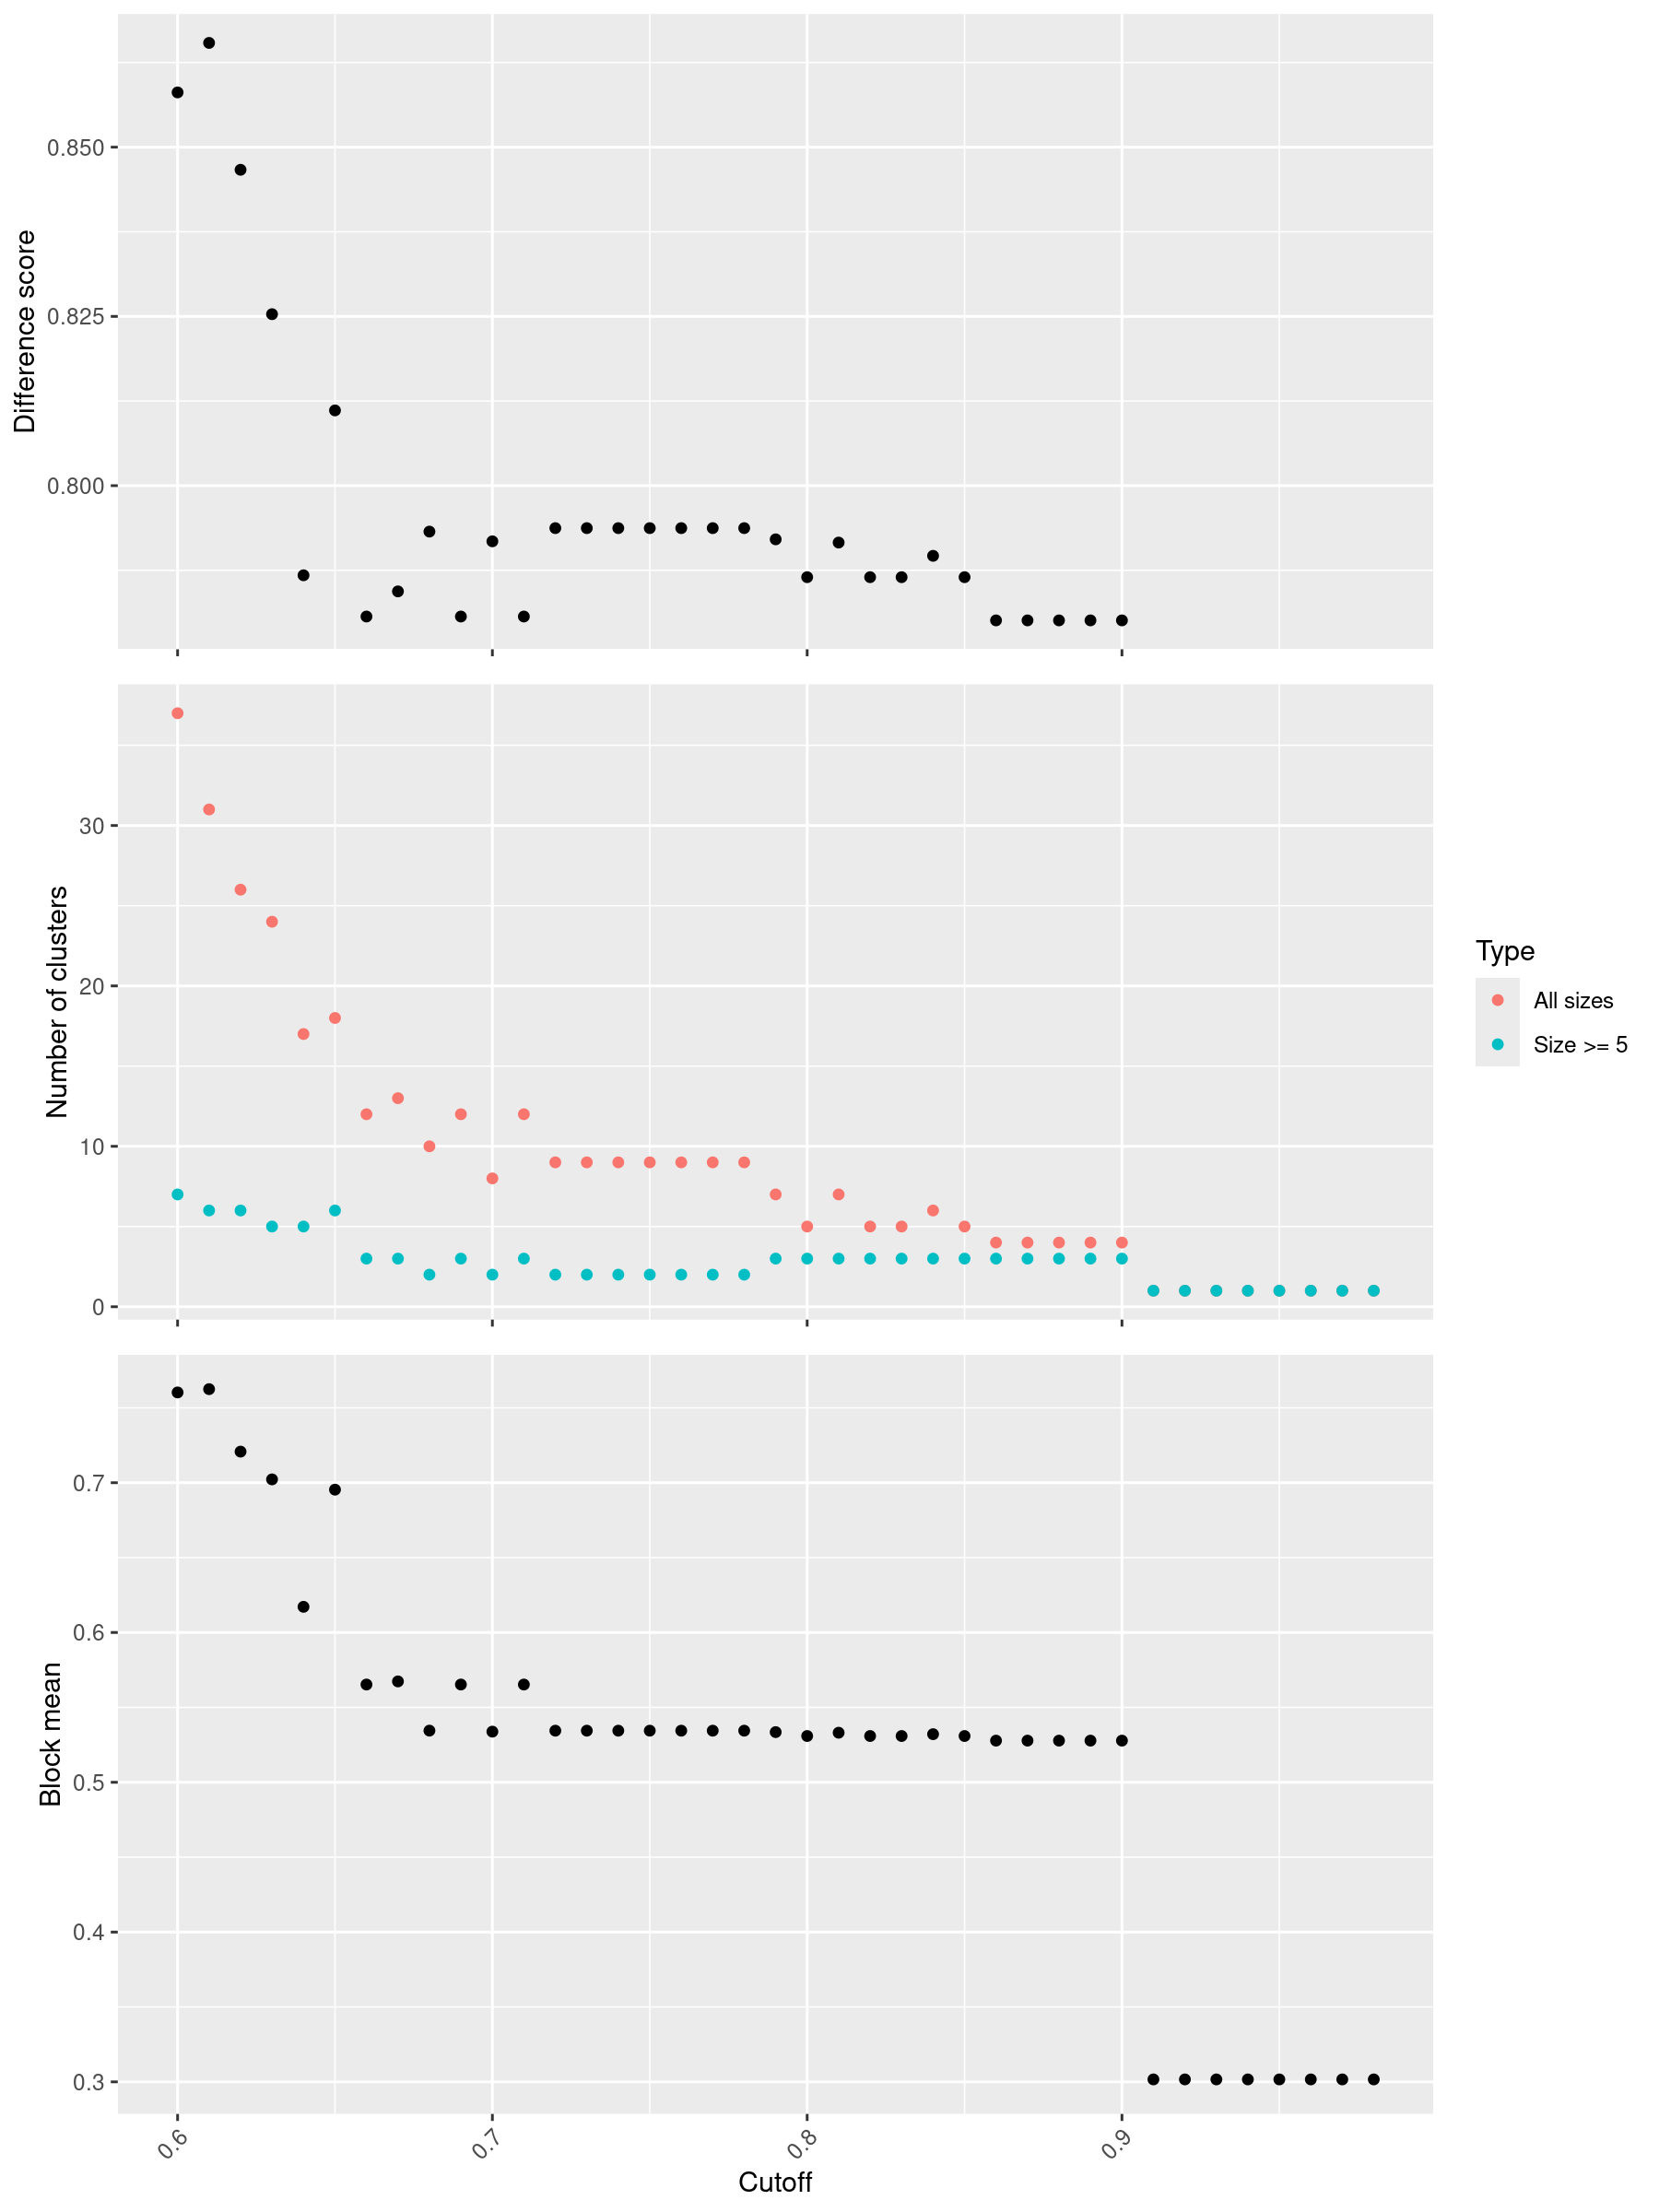

In [11]:
# Uncomment after running select_cutoff() above.
display(Image(filename="../../out/enrichment_analysis/simona/all_pc_transcript/down5p_pc_go_bp_select_cutoff.png"))

In [12]:
%%R
png(
  "../../out/enrichment_analysis/simona/all_pc_transcript/down5p_pc_go_bp_simplifyGO.png",
  width = 2500,
  height = 1700,
  res = 300
)
df_bp <- simplifyGO(
  mat_bp,
  # 0.8 sits just before the block-mean collapse on select_cutoff()
  control = list(cutoff = 0.8), # add cutoff parameter
  verbose = FALSE,
  padding = unit(c(7.5, 7.5, 7.5, 7.5), "mm"),
  word_cloud_grob_param = list(
    fontsize = c(15, 25),
    max_width = 70,
    word_space = 4
  )
)
invisible(dev.off())

print(table(df_bp$cluster))


 1  2  3  4  5 
47 49  4  8  2 


Perform keywords enrichment for 5 GO lists...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...


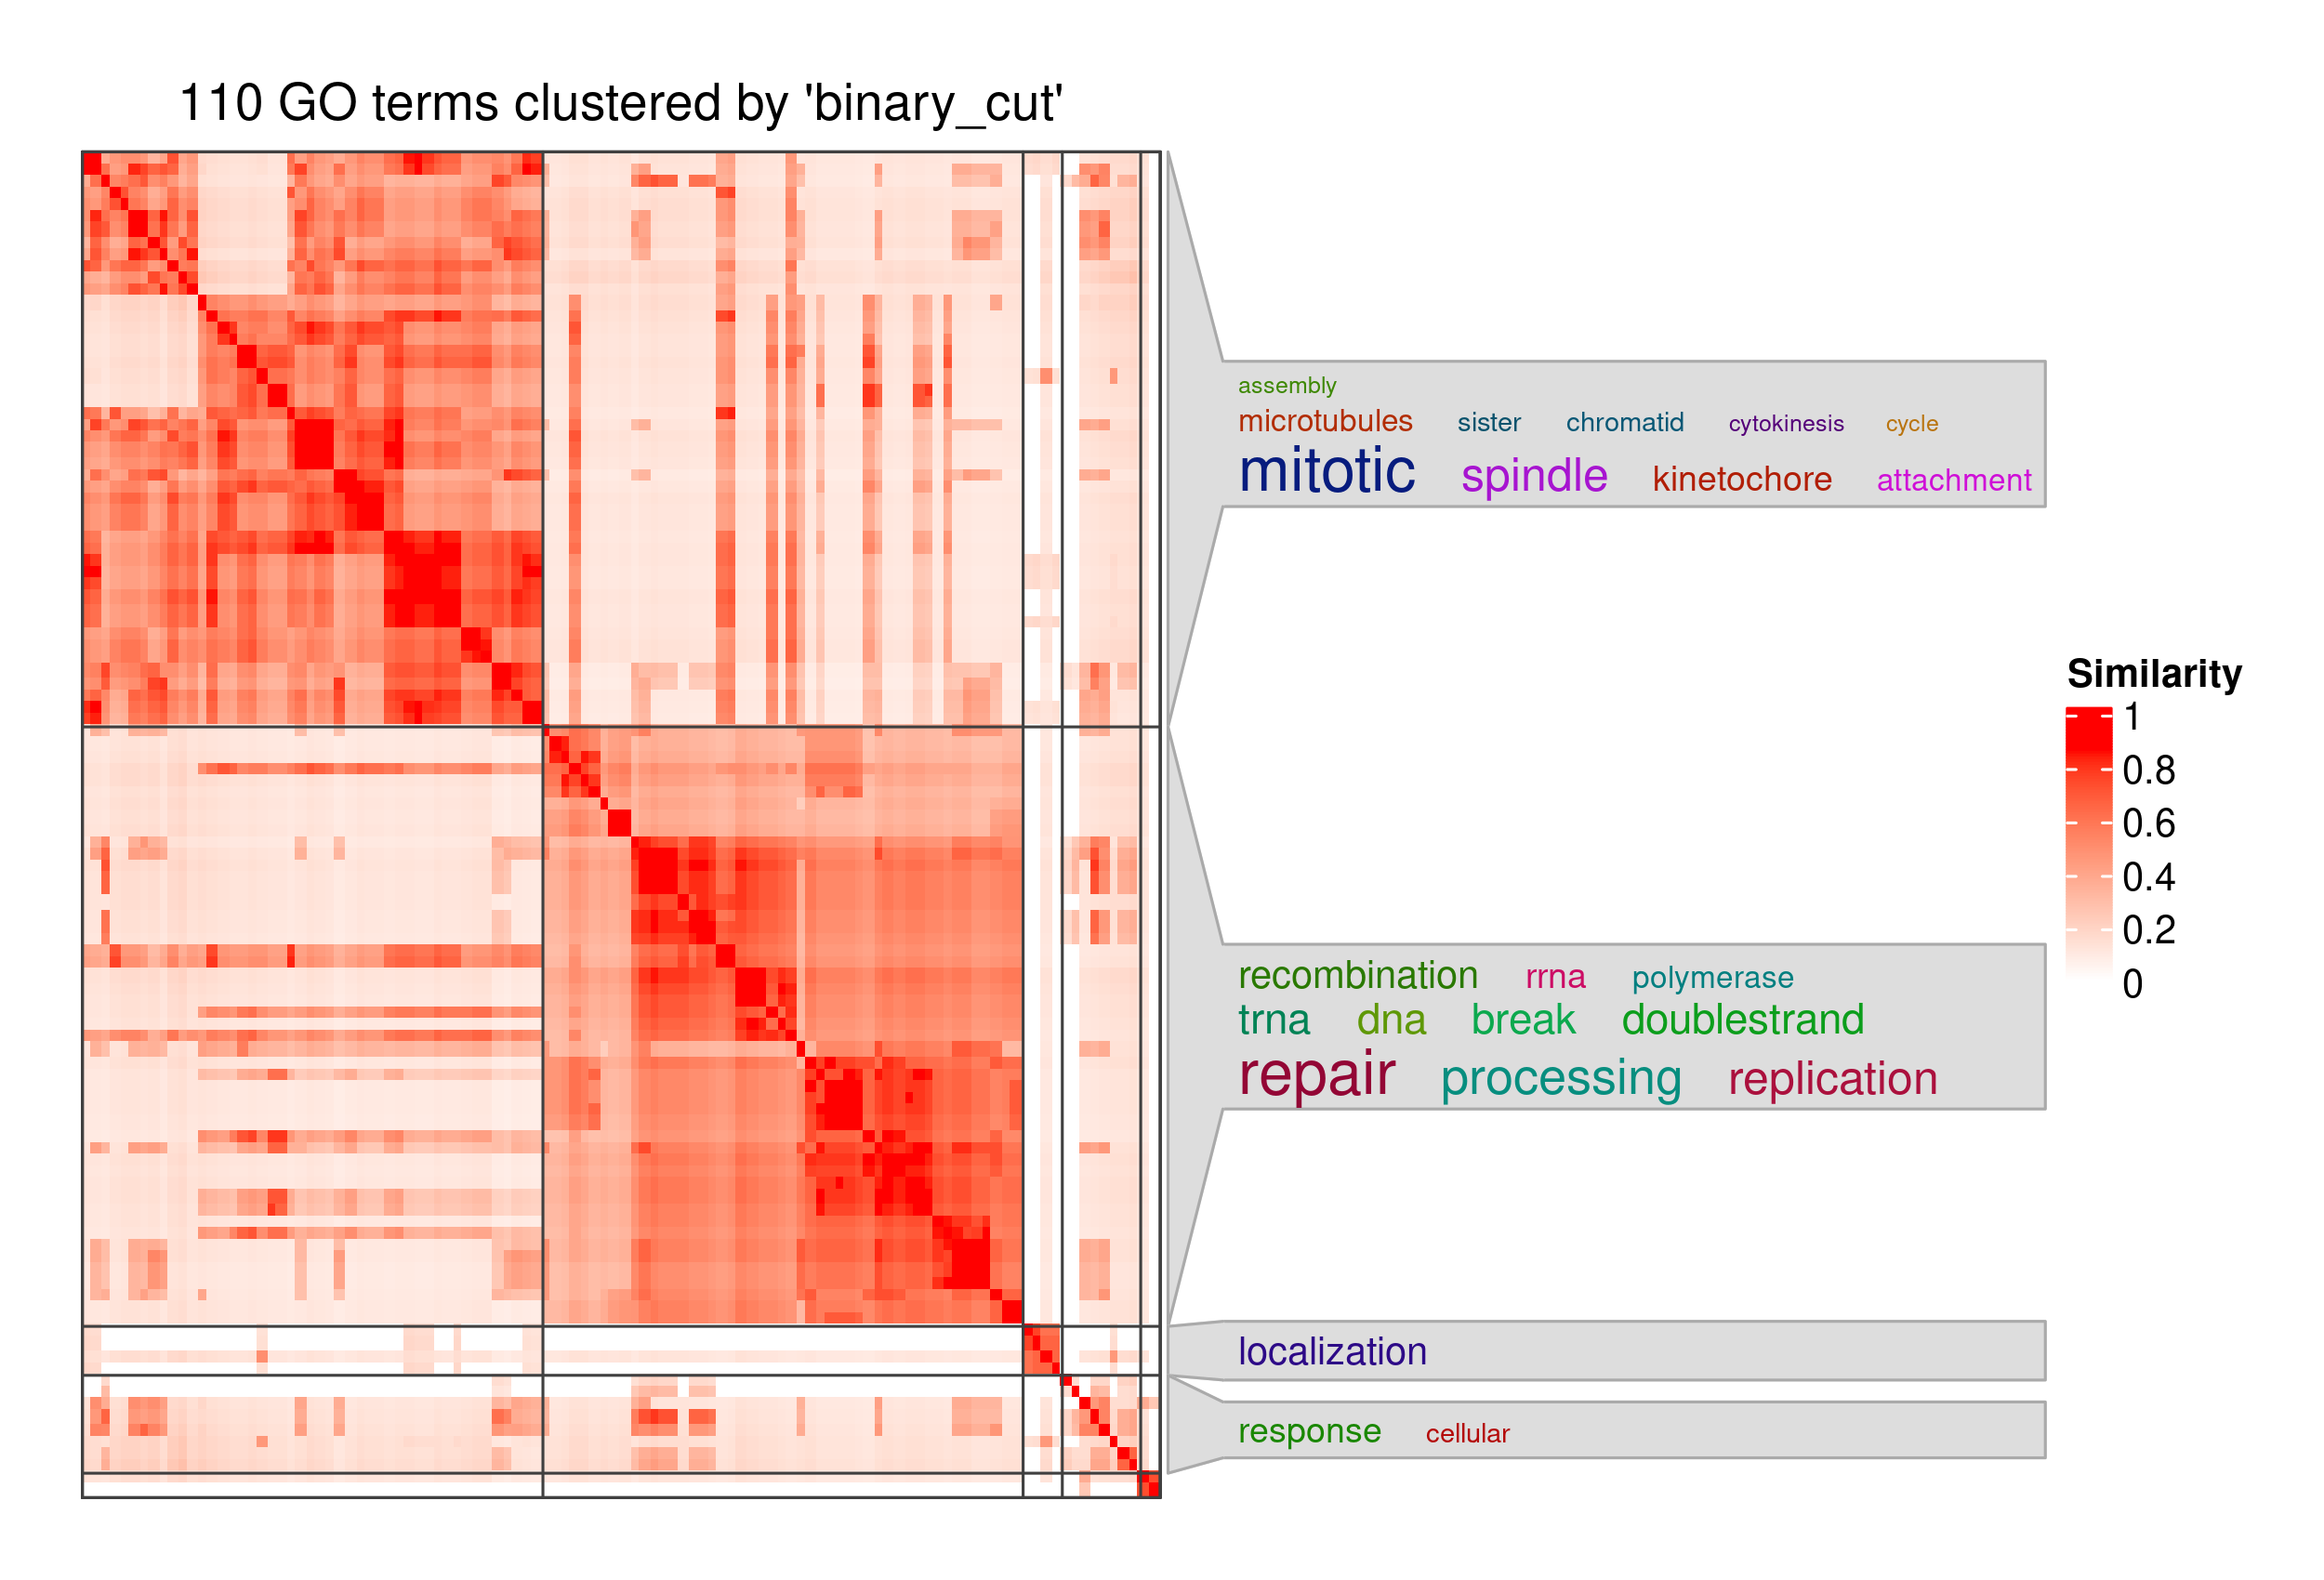

In [13]:
display(Image(filename="../../out/enrichment_analysis/simona/all_pc_transcript/down5p_pc_go_bp_simplifyGO.png"))

&nbsp;

&nbsp;

&nbsp;

## Molecular Function (MF)

In [14]:
%%R -i go_ids_mf
# https://jokergoo.github.io/simona/articles/v02_GO.html
go_ids_mf <- as.character(go_ids_mf)

dag_mf <- dag_filter(
  dag_go,
  terms = mcols(dag_go)$id[which(mcols(dag_go)$namespace == "molecular_function")]
)
print(dag_mf)

# Do not print the matrix. The enriched term set is too large for the notebook.
mat_mf <- term_sim(dag_mf, go_ids_mf, method = "Sim_WP_1994")
print(dim(mat_mf))

An ontology_DAG object:
  Source: go, releases/2026-07-26 
  10041 terms / 12472 relations
  Root: GO:0003674 
  Terms: GO:0000006, GO:0000007, GO:0000009, GO:0000010, ...
  Max depth: 12 
  Avg number of parents: 1.24
  Avg number of children: 1.31
  Aspect ratio: 384.8:1 (based on the longest distance from root)
                531.12:1 (based on the shortest distance from root)
  Relations: is_a, negatively_regulates, part_of, positively_regulates,
             regulates
  Relation types may have hierarchical relations.

With the following columns in the metadata data frame:
  id, short_id, name, namespace, definition
[1] 58 58


In [15]:
%%R
# cowplot is required by select_cutoff()
if (!requireNamespace("cowplot", quietly = TRUE)) {
  install.packages("cowplot", repos = "https://cloud.r-project.org")
}

# Default cutoff grid is 0.6 to 0.98 by 0.01
png(
  "../../out/enrichment_analysis/simona/all_pc_transcript/down5p_pc_go_mf_select_cutoff.png",
  width = 1800,
  height = 2400,
  res = 200
)
select_cutoff(mat_mf)
invisible(dev.off())

1/39, cutoff = 0.6...
2/39, cutoff = 0.61...
3/39, cutoff = 0.62...
4/39, cutoff = 0.63...
5/39, cutoff = 0.64...
6/39, cutoff = 0.65...
7/39, cutoff = 0.66...
8/39, cutoff = 0.67...
9/39, cutoff = 0.68...
10/39, cutoff = 0.69...
11/39, cutoff = 0.7...
12/39, cutoff = 0.71...
13/39, cutoff = 0.72...
14/39, cutoff = 0.73...
15/39, cutoff = 0.74...
16/39, cutoff = 0.75...
17/39, cutoff = 0.76...
18/39, cutoff = 0.77...
19/39, cutoff = 0.78...
20/39, cutoff = 0.79...
21/39, cutoff = 0.8...
22/39, cutoff = 0.81...
23/39, cutoff = 0.82...
24/39, cutoff = 0.83...
25/39, cutoff = 0.84...
26/39, cutoff = 0.85...
27/39, cutoff = 0.86...
28/39, cutoff = 0.87...
29/39, cutoff = 0.88...
30/39, cutoff = 0.89...
31/39, cutoff = 0.9...
32/39, cutoff = 0.91...
33/39, cutoff = 0.92...
34/39, cutoff = 0.93...
35/39, cutoff = 0.94...
36/39, cutoff = 0.95...
37/39, cutoff = 0.96...
38/39, cutoff = 0.97...
39/39, cutoff = 0.98...


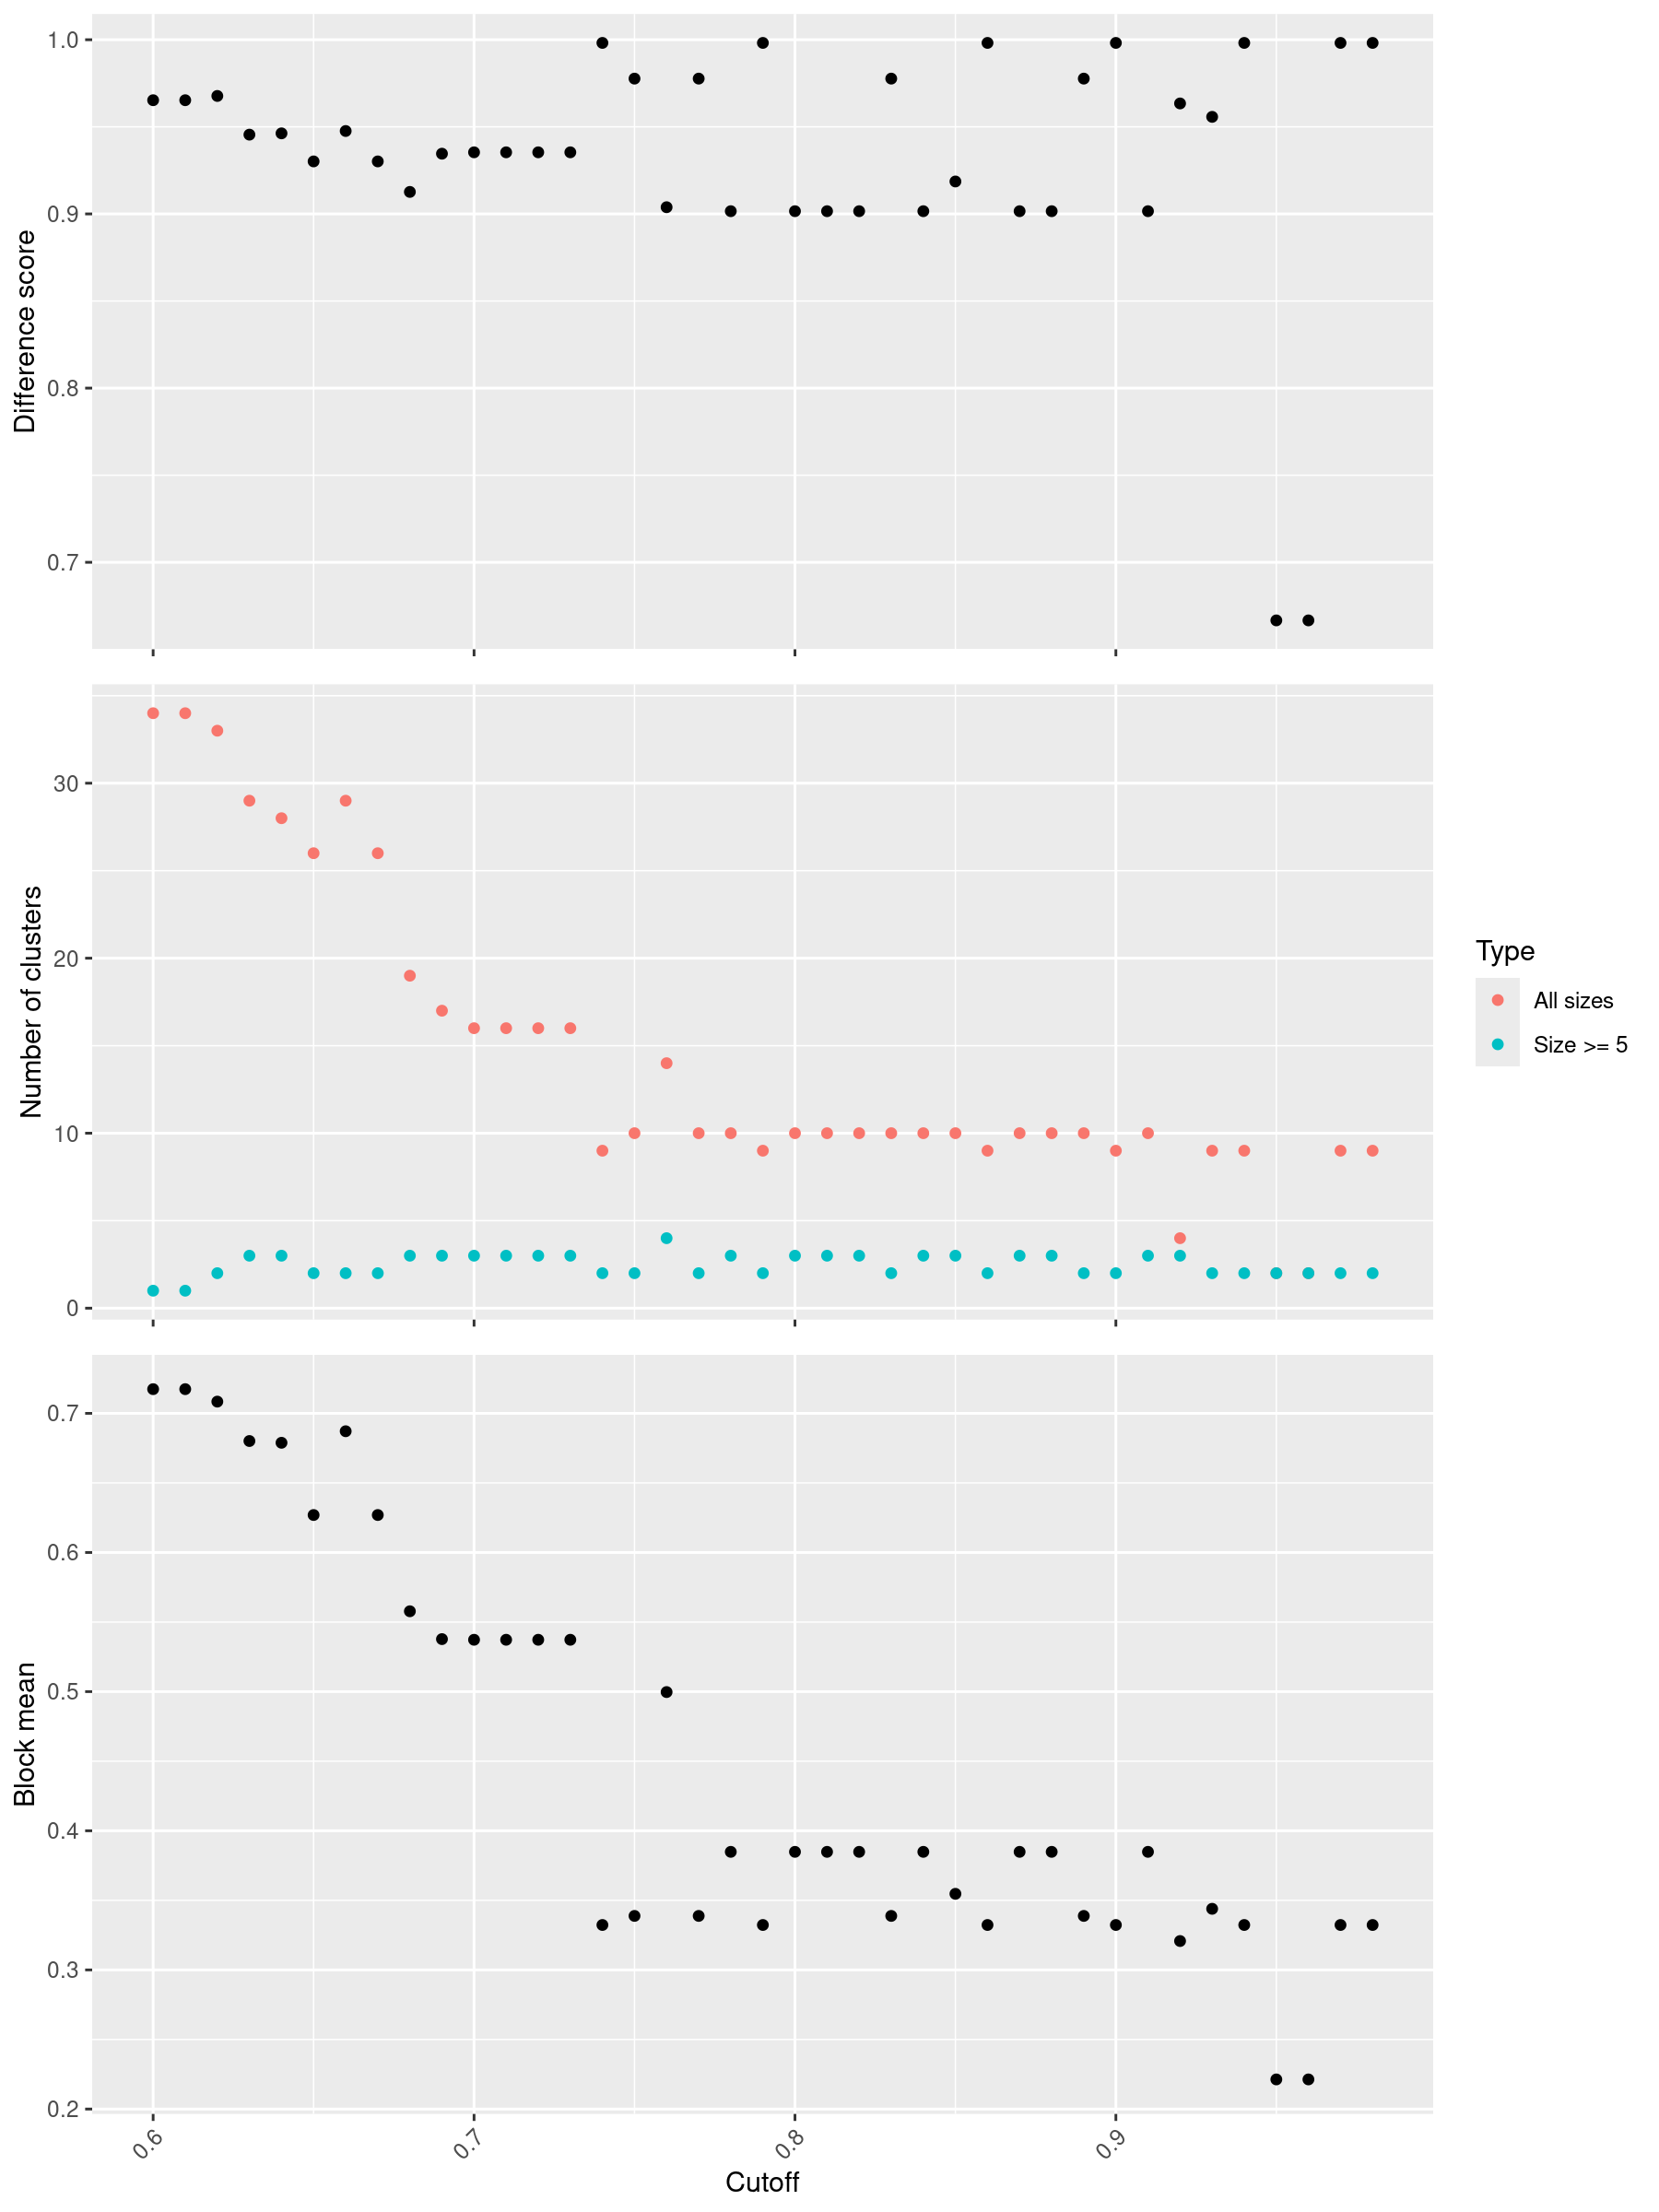

In [16]:
# Uncomment after running select_cutoff() above.
display(Image(filename="../../out/enrichment_analysis/simona/all_pc_transcript/down5p_pc_go_mf_select_cutoff.png"))

In [17]:
%%R
png(
  "../../out/enrichment_analysis/simona/all_pc_transcript/down5p_pc_go_mf_simplifyGO.png",
  width = 2300,
  height = 1700,
  res = 300
)
df_mf <- simplifyGO(
  mat_mf,
  verbose = FALSE,
  control = list(cutoff = 0.8), # add cutoff parameter
  padding = unit(c(7.5, 7.5, 7.5, 7.5), "mm"),
  word_cloud_grob_param = list(
    fontsize = c(15, 25),
    max_width = 70,
    word_space = 4
  )
)
invisible(dev.off())

print(table(df_mf$cluster))


 1  2  3  4  5  6  7  8  9 
24  1  3  1 24  1  1  2  1 


Perform keywords enrichment for 9 GO lists...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...


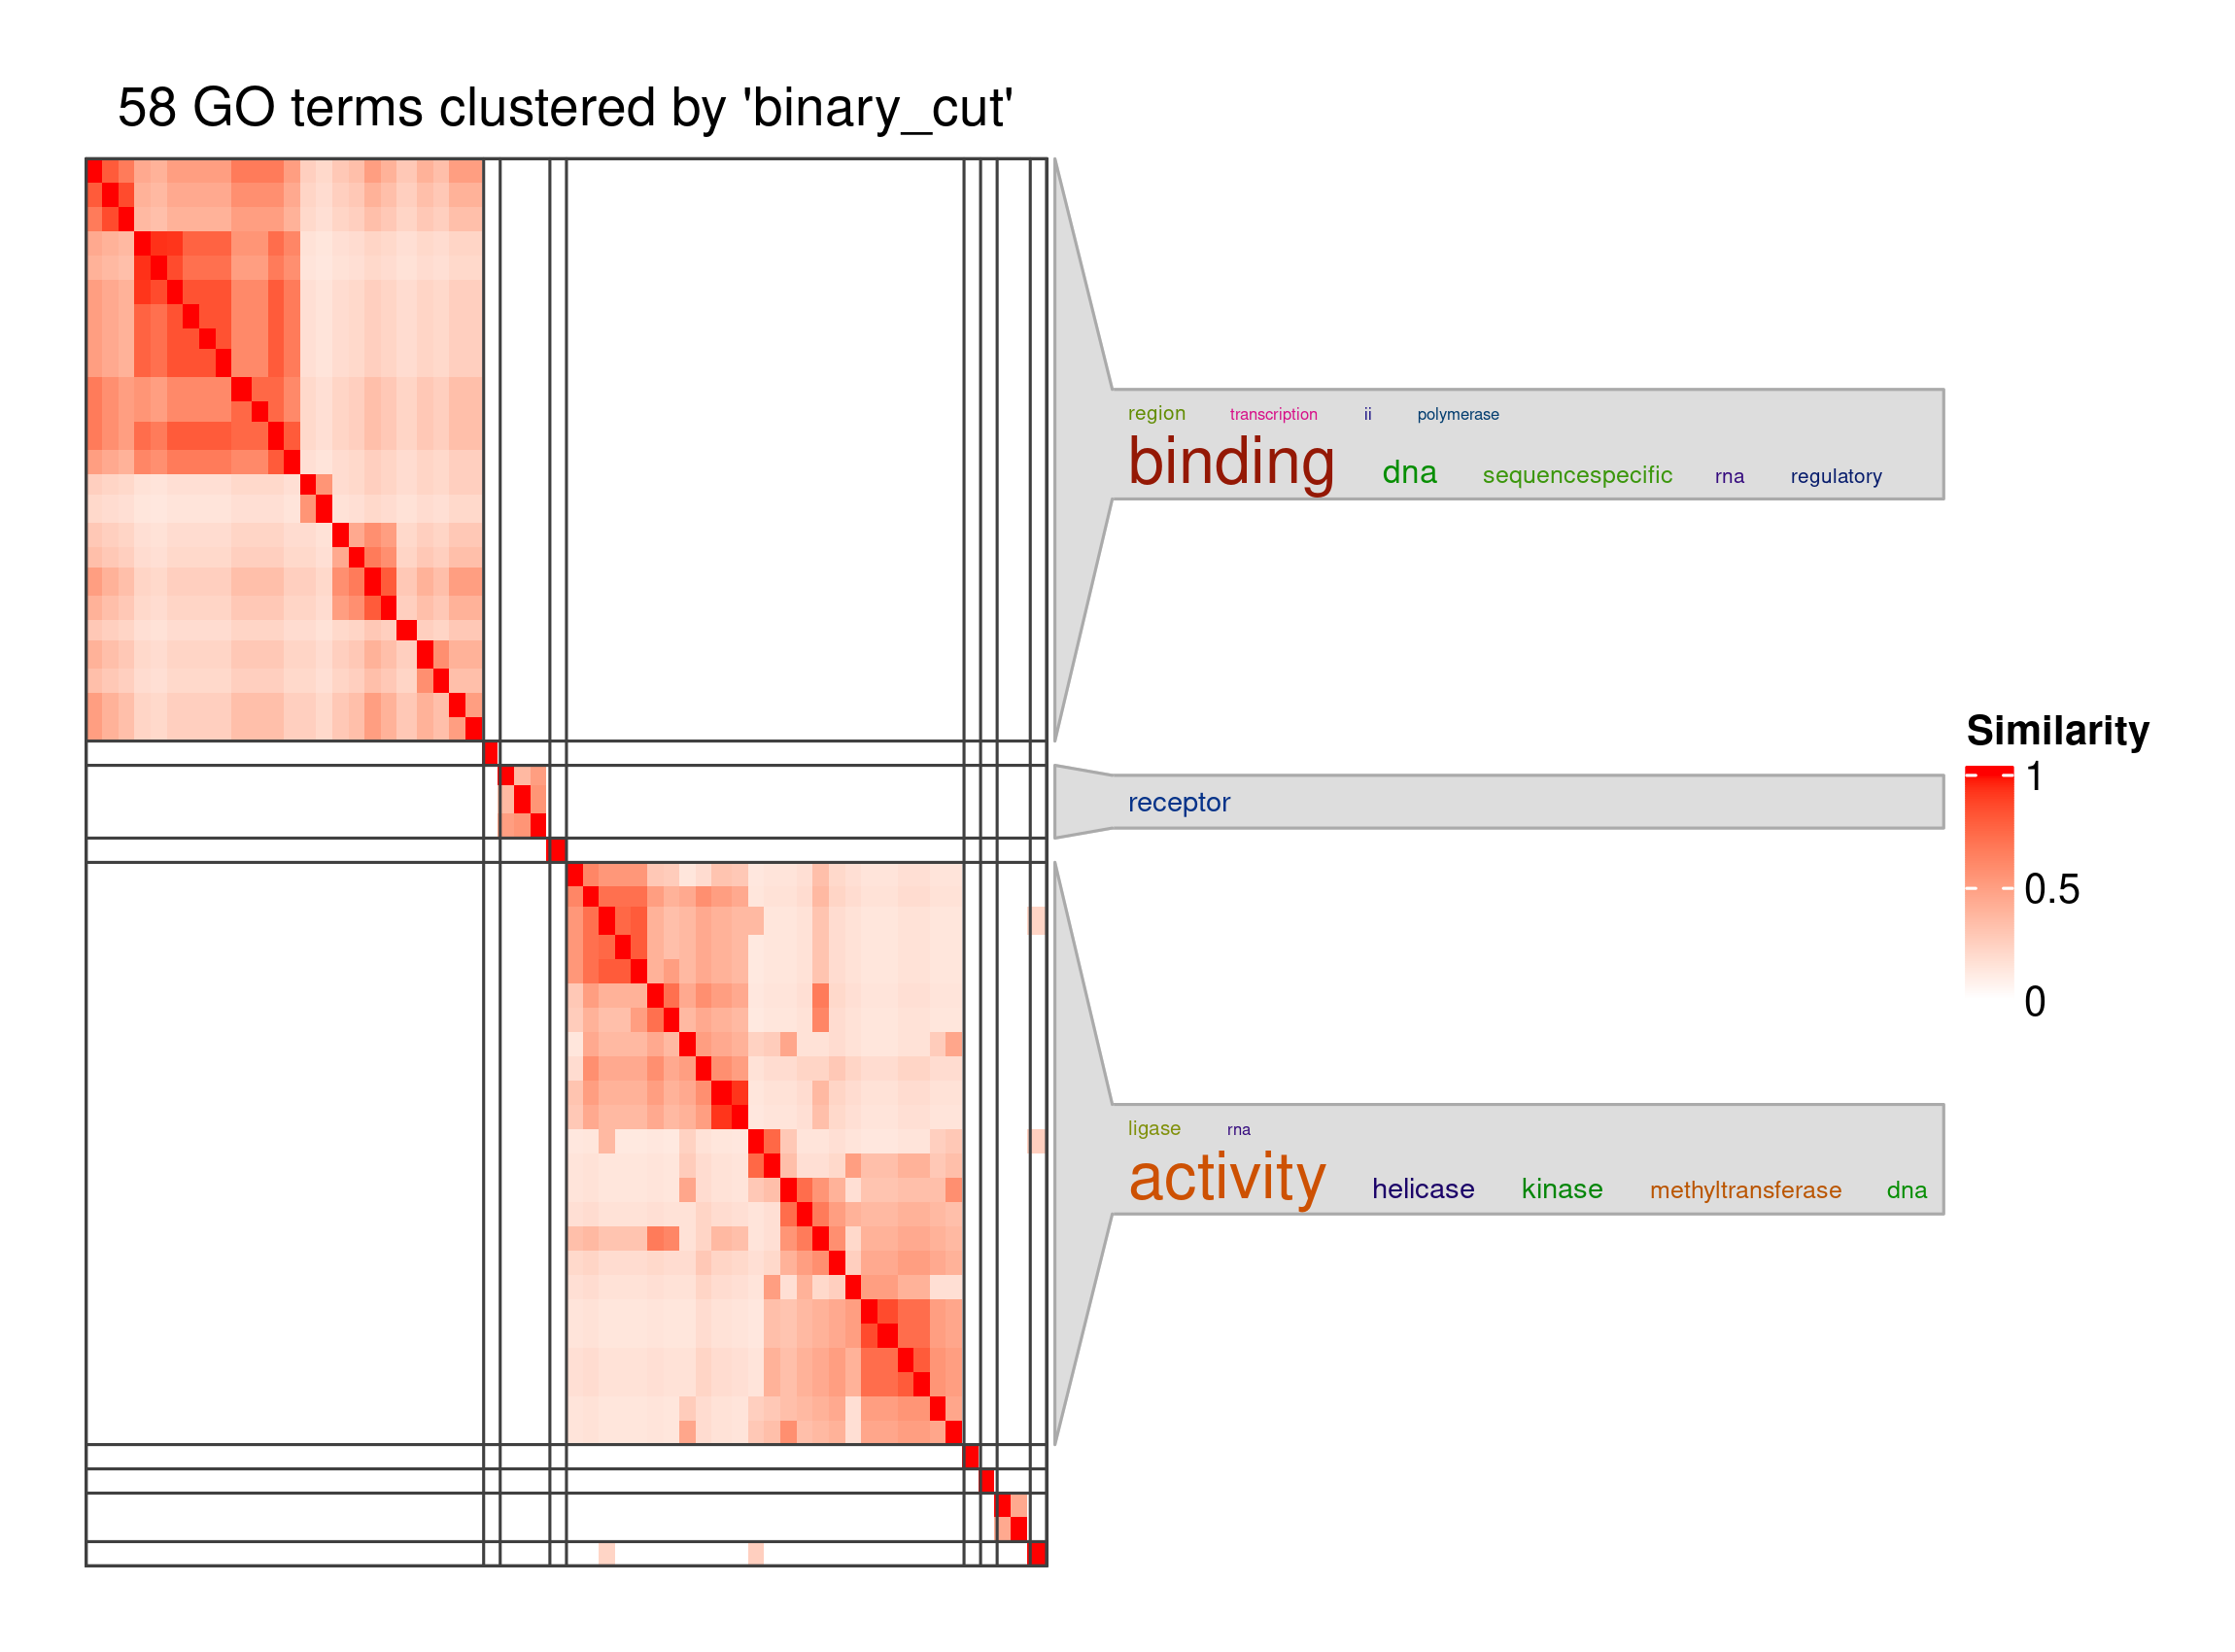

In [18]:
display(Image(filename="../../out/enrichment_analysis/simona/all_pc_transcript/down5p_pc_go_mf_simplifyGO.png"))

&nbsp;

&nbsp;

## Cellular Component (CC)

In [19]:
%%R -i go_ids_cc
# https://jokergoo.github.io/simona/articles/v02_GO.html
go_ids_cc <- as.character(go_ids_cc)

dag_cc <- dag_filter(
  dag_go,
  terms = mcols(dag_go)$id[which(mcols(dag_go)$namespace == "cellular_component")]
)
print(dag_cc)

# Do not print the matrix. The enriched term set is too large for the notebook.
mat_cc <- term_sim(dag_cc, go_ids_cc, method = "Sim_WP_1994")
print(dim(mat_cc))

An ontology_DAG object:
  Source: go, releases/2026-07-26 
  4077 terms / 6496 relations
  Root: GO:0005575 
  Terms: GO:0000015, GO:0000109, GO:0000110, GO:0000111, ...
  Max depth: 14 
  Avg number of parents: 1.59
  Avg number of children: 1.65
  Aspect ratio: 57.55:1 (based on the longest distance from root)
                172.71:1 (based on the shortest distance from root)
  Relations: is_a, part_of

With the following columns in the metadata data frame:
  id, short_id, name, namespace, definition
[1] 75 75


In [20]:
%%R
# cowplot is required by select_cutoff()
if (!requireNamespace("cowplot", quietly = TRUE)) {
  install.packages("cowplot", repos = "https://cloud.r-project.org")
}

# Default cutoff grid is 0.6 to 0.98 by 0.01
png(
  "../../out/enrichment_analysis/simona/all_pc_transcript/down5p_pc_go_cc_select_cutoff.png",
  width = 1800,
  height = 2400,
  res = 200
)
select_cutoff(mat_cc)
invisible(dev.off())

1/39, cutoff = 0.6...
2/39, cutoff = 0.61...
3/39, cutoff = 0.62...
4/39, cutoff = 0.63...
5/39, cutoff = 0.64...
6/39, cutoff = 0.65...
7/39, cutoff = 0.66...
8/39, cutoff = 0.67...
9/39, cutoff = 0.68...
10/39, cutoff = 0.69...
11/39, cutoff = 0.7...
12/39, cutoff = 0.71...
13/39, cutoff = 0.72...
14/39, cutoff = 0.73...
15/39, cutoff = 0.74...
16/39, cutoff = 0.75...
17/39, cutoff = 0.76...
18/39, cutoff = 0.77...
19/39, cutoff = 0.78...
20/39, cutoff = 0.79...
21/39, cutoff = 0.8...
22/39, cutoff = 0.81...
23/39, cutoff = 0.82...
24/39, cutoff = 0.83...
25/39, cutoff = 0.84...
26/39, cutoff = 0.85...
27/39, cutoff = 0.86...
28/39, cutoff = 0.87...
29/39, cutoff = 0.88...
30/39, cutoff = 0.89...
31/39, cutoff = 0.9...
32/39, cutoff = 0.91...
33/39, cutoff = 0.92...
34/39, cutoff = 0.93...
35/39, cutoff = 0.94...
36/39, cutoff = 0.95...
37/39, cutoff = 0.96...
38/39, cutoff = 0.97...
39/39, cutoff = 0.98...


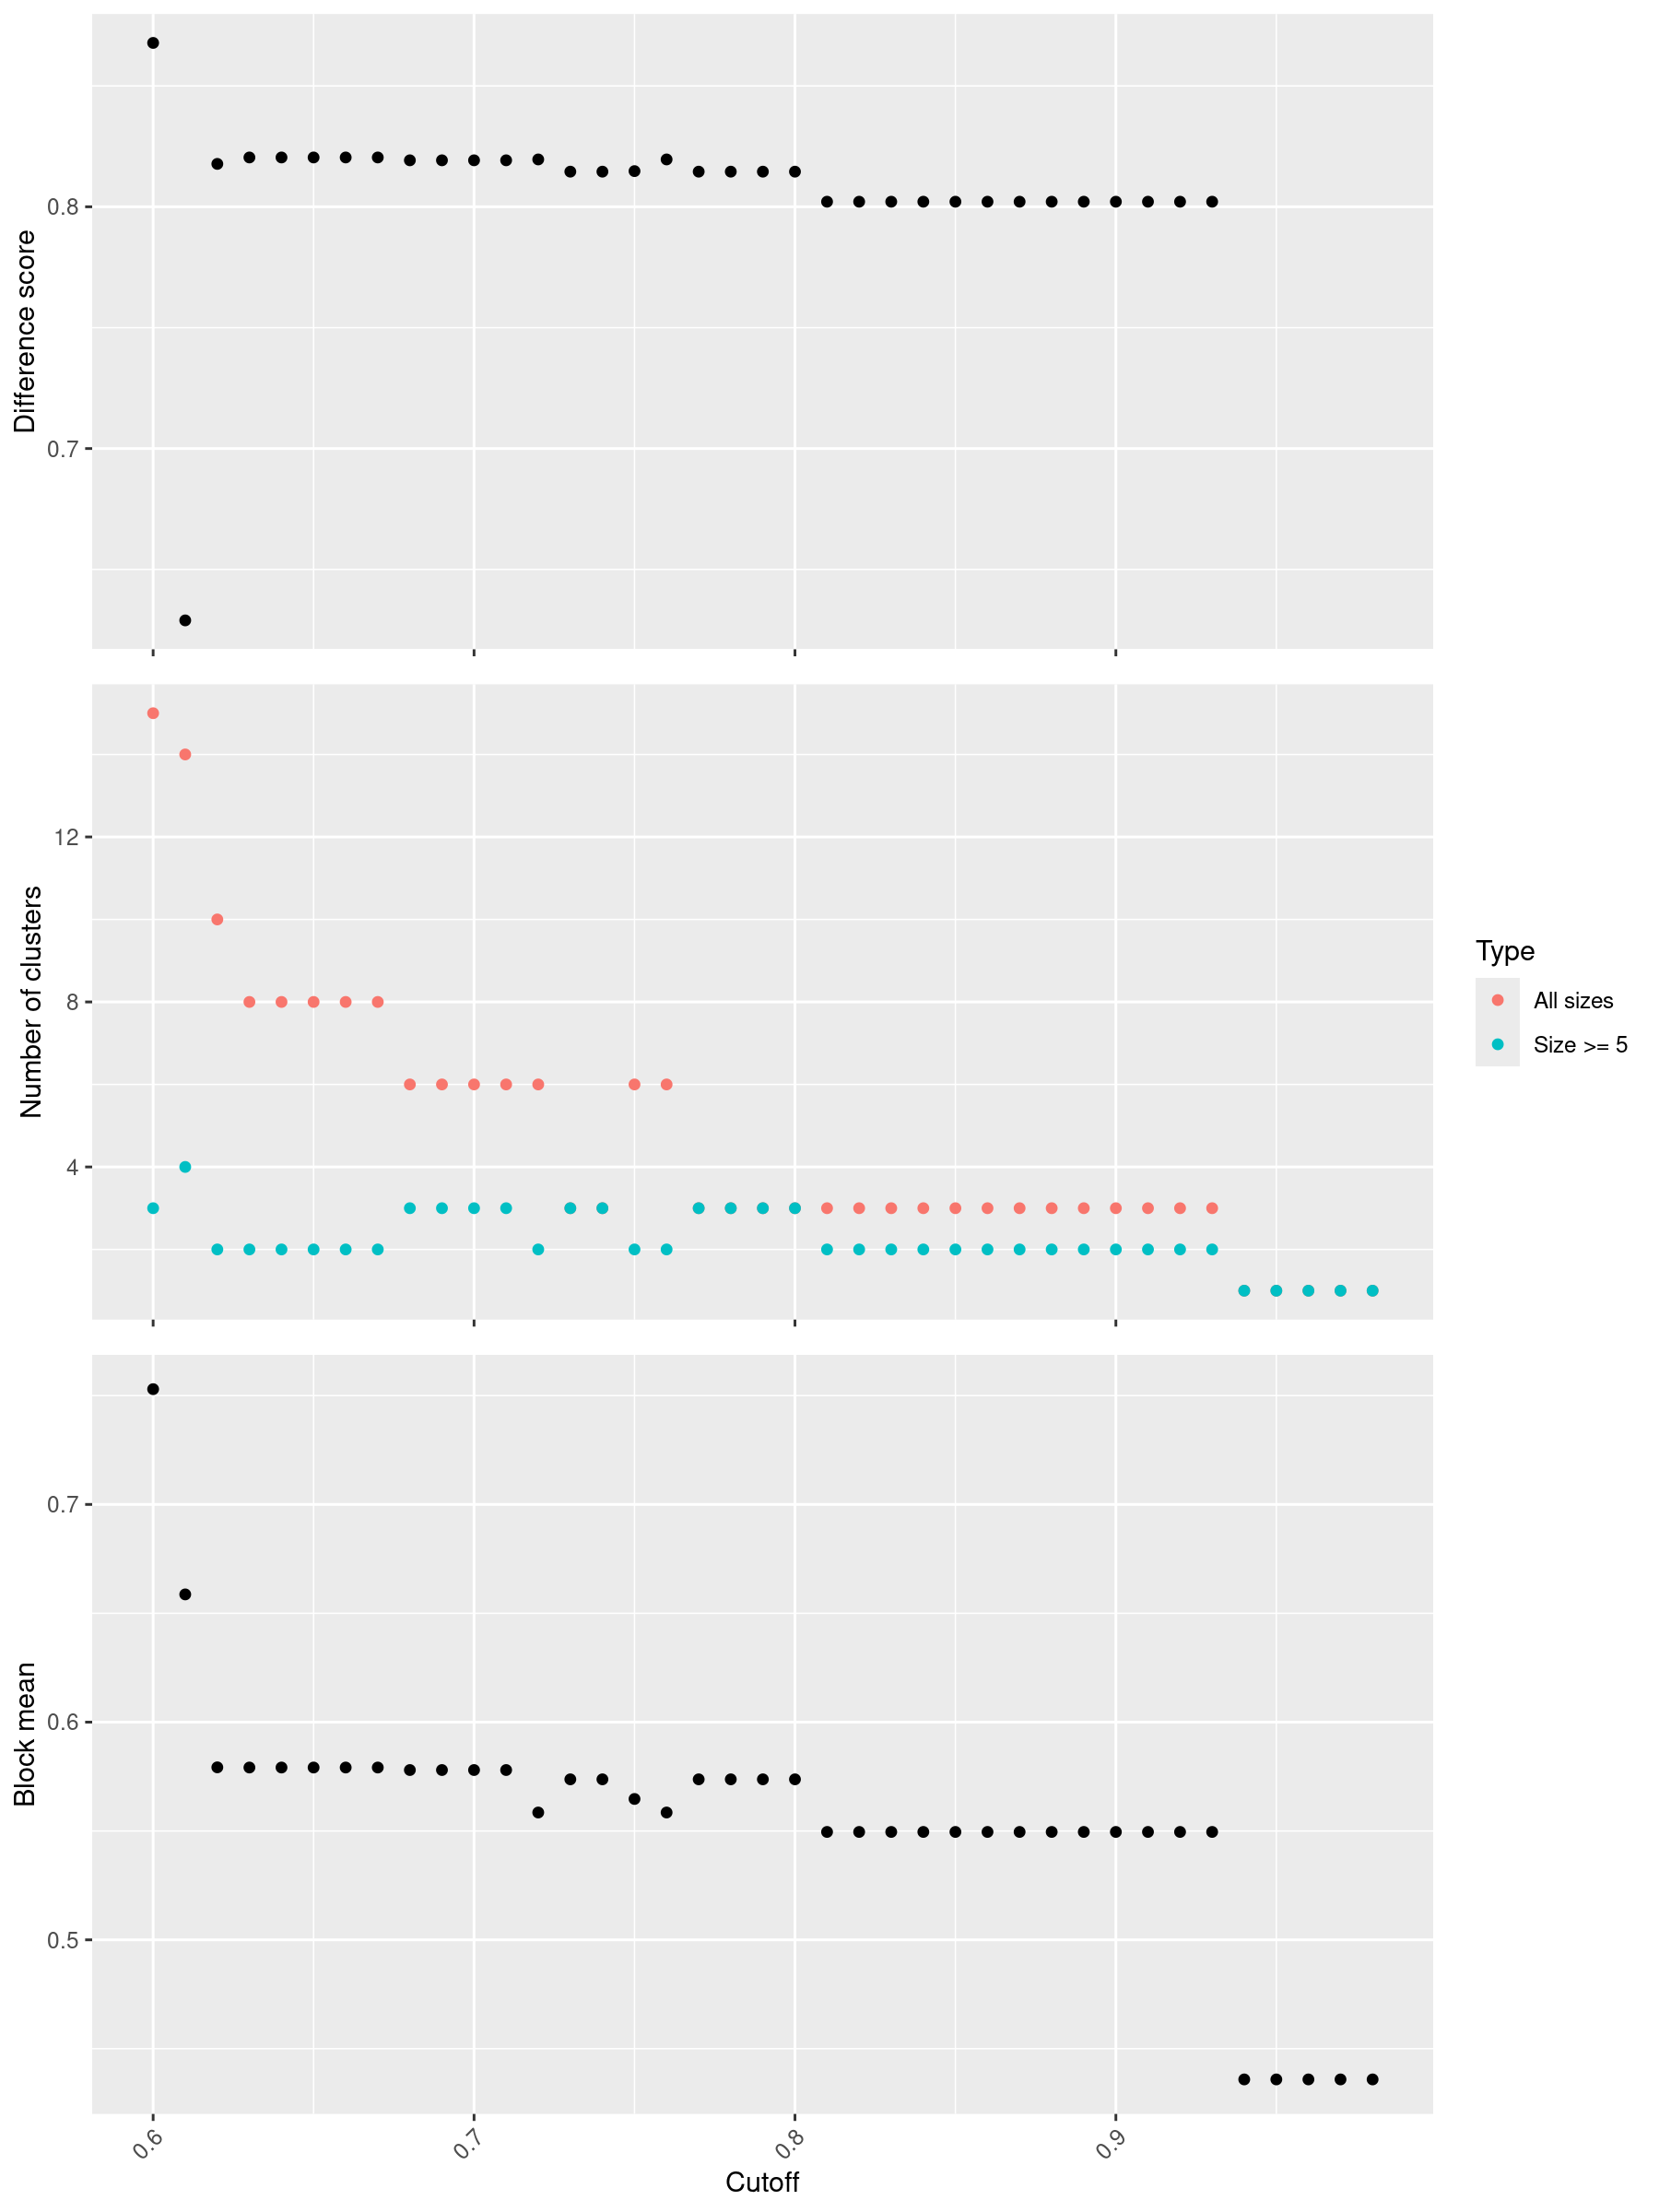

In [21]:
# Uncomment after running select_cutoff() above.
display(Image(filename="../../out/enrichment_analysis/simona/all_pc_transcript/down5p_pc_go_cc_select_cutoff.png"))

In [22]:
%%R
png(
  "../../out/enrichment_analysis/simona/all_pc_transcript/down5p_pc_go_cc_simplifyGO.png",
  width = 2300,
  height = 1700,
  res = 300
)
df_cc <- simplifyGO(
  mat_cc,
  verbose = FALSE,
  control = list(cutoff = 0.8), # add cutoff parameter
  padding = unit(c(7.5, 7.5, 7.5, 7.5), "mm"),
  word_cloud_grob_param = list(
    fontsize = c(15, 25),
    max_width = 70,
    word_space = 4
  )
)
invisible(dev.off())

print(table(df_cc$cluster))


 1  2  3 
10 59  6 


Perform keywords enrichment for 3 GO lists...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...


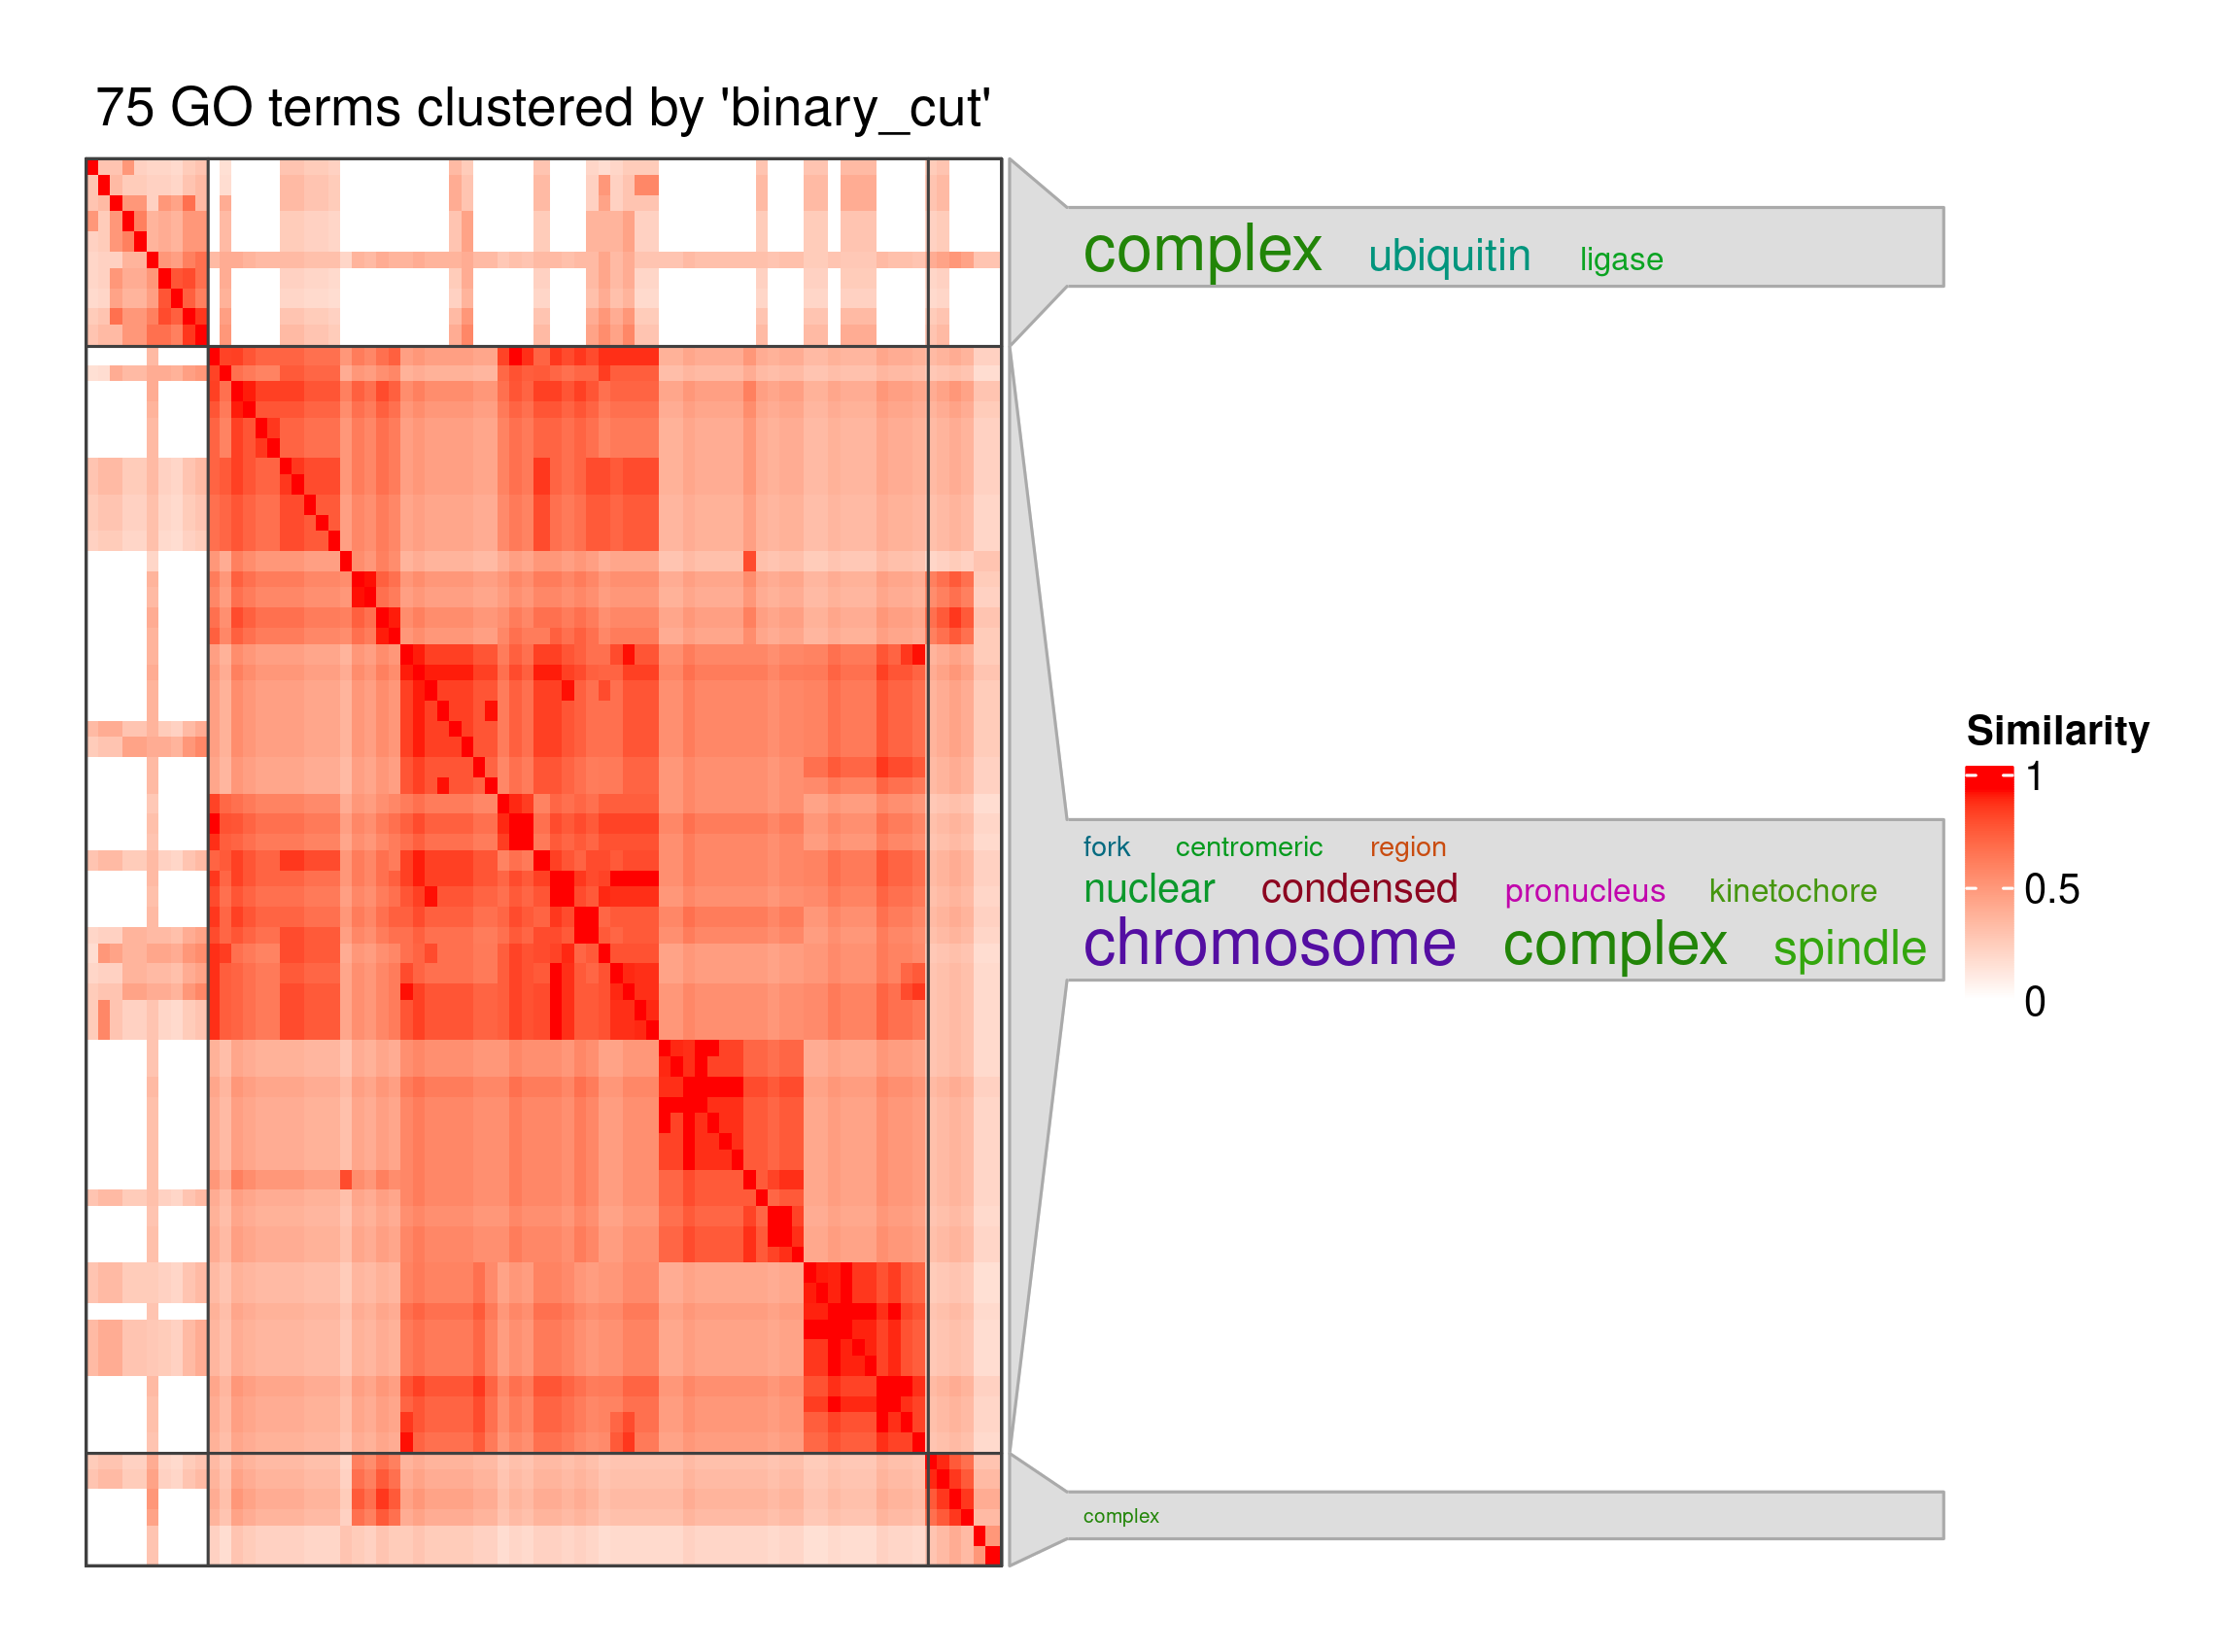

In [23]:
display(Image(filename="../../out/enrichment_analysis/simona/all_pc_transcript/down5p_pc_go_cc_simplifyGO.png"))

&nbsp;

&nbsp;

## Cluster membership

- `simplifyGO()` の戻り値 `df_bp` / `df_mf` / `df_cc` を Polars に渡す
- `cluster` はヒートマップ上の番号と同じ。上から 1, 2, 3, ...
- 上の BP / MF / CC の `simplifyGO()` セルを実行したあとに実行する


In [24]:
import rpy2.robjects as ro

def r_simplifygo_cluster(r_name: str, namespace: str) -> pl.DataFrame:
    # simplifyGO() returns id (character) and cluster (numeric) in the R session.
    rdf = ro.globalenv[r_name]
    return pl.DataFrame(
        {
            "id": list(rdf.rx2("id")),
            "cluster": list(rdf.rx2("cluster")),
        }
    ).with_columns(
        pl.col("id").cast(pl.String),
        pl.col("cluster").cast(pl.Int64),
        pl.lit(namespace).alias("NS"),
    )

# One row per GO term. cluster matches the number on the simplifyGO heatmap.
down5p_pc_go_cluster = (
    pl.concat(
        [
            r_simplifygo_cluster("df_bp", "BP"),
            r_simplifygo_cluster("df_mf", "MF"),
            r_simplifygo_cluster("df_cc", "CC"),
        ],
        how="vertical",
    )
    .join(
        down5p_pc_enrichment_result_go_list.rename({"# GO": "id"}),
        on=["id", "NS"],
        how="left",
    )
    .select("NS", "cluster", "id", "name", "enrichment")
    .sort("NS", "cluster", "id")
)

# GO IDs and names belonging to each cluster, in heatmap order.
down5p_pc_go_cluster_list = (
    down5p_pc_go_cluster
    .group_by("NS", "cluster", maintain_order=True)
    .agg(
        pl.len().alias("n_go"),
        pl.col("id").alias("go_id"),
        pl.col("name"),
    )
    .with_columns(
        # list.join needs a list[str] column that already exists.
        pl.col("go_id").list.join("; ").alias("go_id"),
        pl.col("name").list.join("; ").alias("name"),
    )
)

display(down5p_pc_go_cluster)

pl.Config.set_tbl_rows(30)
display(down5p_pc_go_cluster_list)


NS,cluster,id,name,enrichment
str,i64,str,str,str
"""BP""",1,"""GO:0000070""","""mitotic sister chromatid segregation""","""e"""
…,…,…,…,…
"""MF""",9,"""GO:0140612""","""DNA damage sensor activity""","""e"""


NS,cluster,n_go,go_id,name
str,i64,u32,str,str
"""BP""",1,47,"""GO:0000070; GO:0000077; GO:0000278; GO:0000280; GO:0000281; GO:0001578; GO:0007019; GO:0007051; GO:0007052; GO:0007057; GO:0007059; GO:0007064; GO:0007076; GO:0007079; GO:0007080; GO:0007094; GO:00070…","""mitotic sister chromatid segregation; DNA damage checkpoint signaling; mitotic cell cycle; nuclear division; mitotic cytokinesis; microtubule bundle formation; microtubule depolymerization; spindle or…"
"""BP""",2,49,"""GO:0000079; GO:0000209; GO:0000387; GO:0000712; GO:0000724; GO:0000727; GO:0000729; GO:0000963; GO:0006260; GO:0006261; GO:0006271; GO:0006281; GO:0006282; GO:0006357; GO:0006364; GO:0006384; GO:00063…","""regulation of cyclin-dependent protein serine/threonine kinase activity; protein polyubiquitination; spliceosomal snRNP assembly; resolution of meiotic recombination intermediates; double-strand break…"
"""BP""",3,4,"""GO:0006606; GO:0034501; GO:0071168; GO:1904491""","""protein import into nucleus; protein localization to kinetochore; protein localization to chromatin; protein localization to ciliary transition zone"""
"""BP""",4,8,"""GO:0008630; GO:0009411; GO:0036465; GO:0072711; GO:0072719; GO:0140374; GO:1902036; GO:2000773""","""intrinsic apoptotic signaling pathway in response to DNA damage; response to UV; synaptic vesicle recycling; cellular response to hydroxyurea; cellular response to cisplatin; antiviral innate immune r…"
"""BP""",5,2,"""GO:0021861; GO:1904693""","""forebrain radial glial cell differentiation; midbrain morphogenesis"""
"""CC""",1,10,"""GO:0000151; GO:0000172; GO:0019005; GO:0030008; GO:0030688; GO:0031464; GO:0031515; GO:0048476; GO:0097550; GO:1990234""","""ubiquitin ligase complex; ribonuclease MRP complex; SCF ubiquitin ligase complex; TRAPP complex; preribosome, small subunit precursor; Cul4A-RING E3 ubiquitin ligase complex; tRNA (m1A) methyltransfer…"
"""CC""",2,59,"""GO:0000228; GO:0000444; GO:0000775; GO:0000776; GO:0000779; GO:0000781; GO:0000785; GO:0000796; GO:0000811; GO:0000812; GO:0000922; GO:0000939; GO:0000940; GO:0001939; GO:0001940; GO:0005634; GO:00056…","""nuclear chromosome; MIS12/MIND type complex; chromosome, centromeric region; kinetochore; condensed chromosome, centromeric region; chromosome, telomeric region; chromatin; condensin complex; GINS com…"
"""CC""",3,6,"""GO:0005737; GO:0005829; GO:0030496; GO:0032797; GO:0034719; GO:0070938""","""cytoplasm; cytosol; midbody; SMN complex; SMN-Sm protein complex; contractile ring"""
"""MF""",1,24,"""GO:0000287; GO:0000976; GO:0000977; GO:0000978; GO:0003676; GO:0003682; GO:0003684; GO:0003688; GO:0003690; GO:0003696; GO:0003697; GO:0003723; GO:0005515; GO:0005524; GO:0008017; GO:0010997; GO:00192…","""magnesium ion binding; transcription cis-regulatory region binding; RNA polymerase II transcription regulatory region sequence-specific DNA binding; RNA polymerase II cis-regulatory region sequence-sp…"


In [25]:
down5p_pc_go_cluster.write_csv(
    "../../out/enrichment_analysis/simona/all_pc_transcript/cluster_list/down5p_pc_go_cluster.tsv",
    separator="\t"
)

down5p_pc_go_cluster_list.write_csv(
    "../../out/enrichment_analysis/simona/all_pc_transcript/cluster_list/down5p_pc_go_cluster_list.tsv",
    separator="\t"
)